In [9]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [10]:
os.getcwd()

'D:\\Projects\\СreditScoring\\notebooks'

## 0. Сбор данных
На выходе этого блока: Короткая витрина базовых факторов и широкая витрина со всеми поведенческими данными

In [11]:
train_df = pd.read_csv('../data/application_train.csv')
# поведенческие данные
"""previous_df = pd.read_csv('../input/competitions/home-credit-default-risk/previous_application.csv')
bureau_df = pd.read_csv('../input/competitions/home-credit-default-risk/bureau.csv')
bureau_balance = pd.read_csv('../input/competitions/home-credit-default-risk/bureau_balance.csv')
cash_df = pd.read_csv('../input/competitions/home-credit-default-risk/POS_CASH_balance.csv')
credit_card_df = pd.read_csv('../input/competitions/home-credit-default-risk/credit_card_balance.csv')
payments_df = pd.read_csv('../input/competitions/home-credit-default-risk/installments_payments.csv')
credit_card_df = pd.read_csv('../input/competitions/home-credit-default-risk/credit_card_balance.csv')
"""

train_df.head(5)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 1. Обработка данных
Базовый подход на исходной витрине.
1. проверка факторов на заполнение и пропуски -> выявить те, где пропуски несут смысловую нагрузку, а где - нет.
2. Проверка на нормальность распределения и выбросы. -> сгруппировать сильно перекошенные и несбалансированные факторы.
3. Проверка на корректность типов данных и корректность значений.
4. Исправление значений, нормализация.

In [12]:
factors = train_df.columns.tolist()
factors.remove('SK_ID_CURR')
factors.remove('TARGET')

In [13]:
train_df[factors].info()
df_stats = train_df[factors].describe()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 120 entries, NAME_CONTRACT_TYPE to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(39), str(16)
memory usage: 281.5 MB


In [14]:
print('Размер датасета:', train_df.shape)
n_entries = train_df.shape[0]
nan_factors = []
for factor in factors:
    missing = train_df[factor].isna().sum()
    if missing > 0:
        print("Пропуски по", factor, ' '*(30-len(factor)), f'{missing/n_entries:.2%}, {missing} набл.')
        nan_factors.append(factor)
print("Всего", len(nan_factors))

Размер датасета: (307511, 122)
Пропуски по AMT_ANNUITY                     0.00%, 12 набл.
Пропуски по AMT_GOODS_PRICE                 0.09%, 278 набл.
Пропуски по NAME_TYPE_SUITE                 0.42%, 1292 набл.
Пропуски по OWN_CAR_AGE                     65.99%, 202929 набл.
Пропуски по OCCUPATION_TYPE                 31.35%, 96391 набл.
Пропуски по CNT_FAM_MEMBERS                 0.00%, 2 набл.
Пропуски по EXT_SOURCE_1                    56.38%, 173378 набл.
Пропуски по EXT_SOURCE_2                    0.21%, 660 набл.
Пропуски по EXT_SOURCE_3                    19.83%, 60965 набл.
Пропуски по APARTMENTS_AVG                  50.75%, 156061 набл.
Пропуски по BASEMENTAREA_AVG                58.52%, 179943 набл.
Пропуски по YEARS_BEGINEXPLUATATION_AVG     48.78%, 150007 набл.
Пропуски по YEARS_BUILD_AVG                 66.50%, 204488 набл.
Пропуски по COMMONAREA_AVG                  69.87%, 214865 набл.
Пропуски по ELEVATORS_AVG                   53.30%, 163891 набл.
Пропуски по ENTRAN

Так как факторы с суффиксами _AVG, _MEDI, _MODE - агрегации, пропуски по ним не несут смысловой информации, это проблема качества данных и треует соотв. обработки.
Остаются факторы:

Из них:
- own_car_age сверить с FLAG_OWN_CAR, свести к одному фактору
- NAME_TYPE_SUITE - число пропусков невелико, можно списать в Unaccompanied
- 'AMT_ANNUITY','AMT_GOODS_PRICE' - также явные ошибки данных
- OCCUPATION_TYPE - можно трактовать как "не указан/скрыл"
- CNT_FAM_MEMBERS - можно трактовать как "не указан/скрыл"
- EXT_SOURCE_1...3 - скор внешнего источника. Трактовать отсутствие как смысловое значение некорректно. Возможно взять только (2),смотреть по корреляции с таргетом
- OBS_30_CNT_SOCIAL_CIRCLE доля пропусков незначительна: приравнять nan к нулю(?)
- AMT_REQ_CREDIT_BUREAU_HOUR - либо ошибка, либо отсутствие данных в бюро. вынести в отдельную категорию.
Пропуски по OBS_30_CNT_SOCIAL_CIRCLE        0.33%, 1021 набл.
Пропуски по DEF_30_CNT_SOCIAL_CIRCLE        0.33%, 1021 набл.
Пропуски по OBS_60_CNT_SOCIAL_CIRCLE        0.33%, 1021 набл.
Пропуски по DEF_60_CNT_SOCIAL_CIRCLE        0.33%, 1021 набл.
Пропуски по DAYS_LAST_PHONE_CHANGE          0.00%, 1 набл.
Пропуски по AMT_REQ_CREDIT_BUREAU_HOUR      13.50%, 41519 набл.
Пропуски по AMT_REQ_CREDIT_BUREAU_DAY       13.50%, 41519 набл.
Пропуски по AMT_REQ_CREDIT_BUREAU_WEEK      13.50%, 41519 набл.
Пропуски по AMT_REQ_CREDIT_BUREAU_MON       13.50%, 41519 набл.
Пропуски по AMT_REQ_CREDIT_BUREAU_QRT       13.50%, 41519 набл.
Пропуски по AMT_REQ_CREDIT_BUREAU_YEAR      13.50%, 41519 набл.

In [15]:
ess_nan_factors = ['AMT_ANNUITY','AMT_GOODS_PRICE','NAME_TYPE_SUITE',
                   'OWN_CAR_AGE','OCCUPATION_TYPE','CNT_FAM_MEMBERS',
                   'EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']


In [16]:
bin_factors = []
cat_factors = []
num_factors = []
for factor in factors:
    if train_df[factor].nunique() <=2:
        bin_factors.append(factor)
    elif train_df[factor].nunique() <=20:
        cat_factors.append(factor)
    else:
        num_factors.append(factor)
print('Binnary factors number:', len(bin_factors))
print('Categorical factors number:', len(cat_factors))
print('Numerical factors number:', len(num_factors))


Binnary factors number: 36
Categorical factors number: 21
Numerical factors number: 63


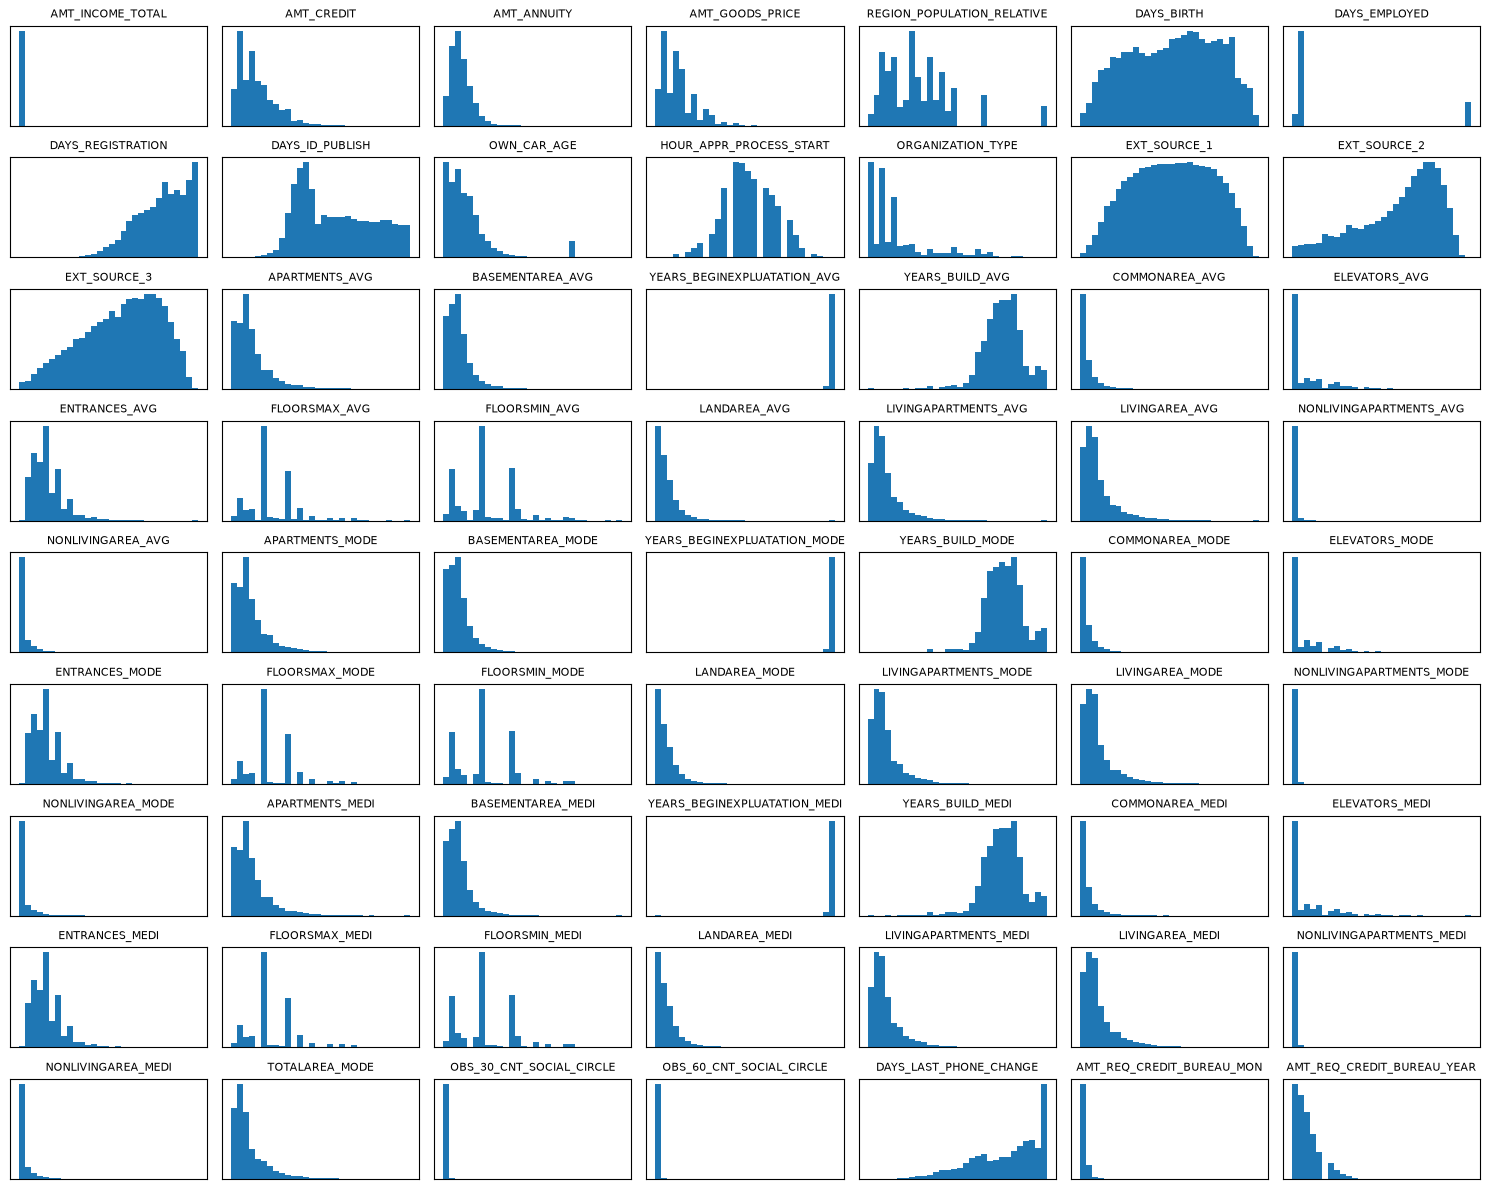

In [17]:
#графики распределений
# отдельно строим по факторам с более чем 2 значения
fig, axis = plt.subplots(9, 7, figsize = (15, 12))
for i, factor in enumerate(num_factors):
    axis[i//7, i%7].hist(train_df[factor].dropna(), bins=30)
    axis[i//7, i%7].set_title(factor, fontsize=8)
    axis[i//7, i%7].set_xticks([])
    axis[i//7, i%7].set_yticks([])
plt.tight_layout()
plt.show()

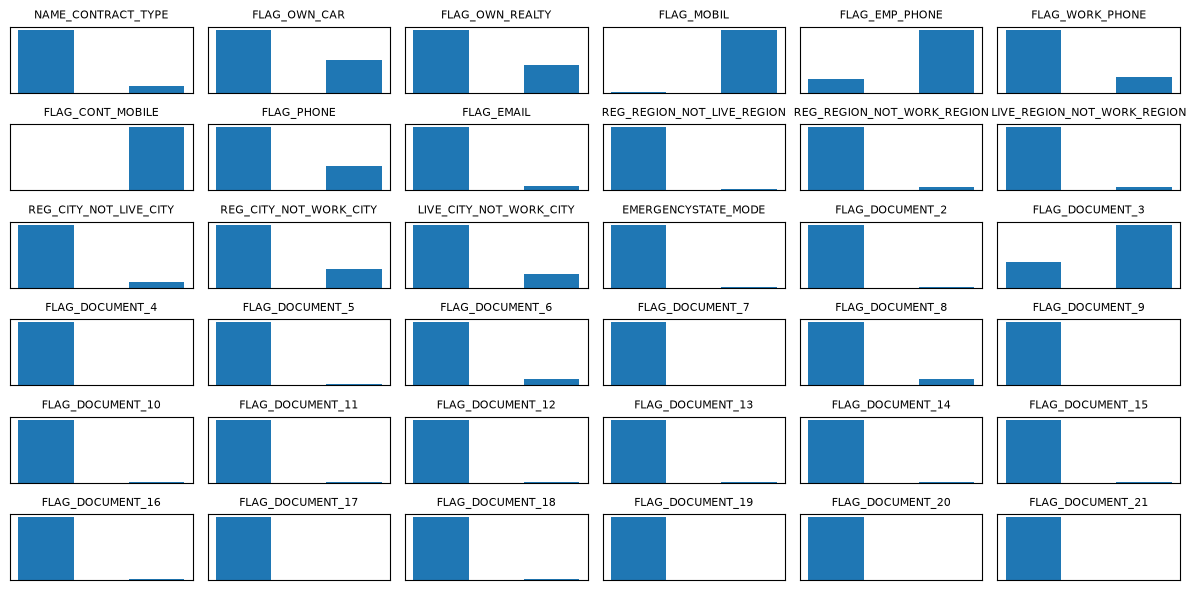

In [18]:
#графики распределений бинарны
fig, axis = plt.subplots(6, 6, figsize = (12, 6))
for i, factor in enumerate(bin_factors):
    axis[i//6, i%6].hist(train_df[factor].dropna(), bins=3)
    axis[i//6, i%6].set_title(factor, fontsize=8)
    axis[i//6, i%6].set_xticks([])
    axis[i//6, i%6].set_yticks([])
plt.tight_layout()
plt.show()

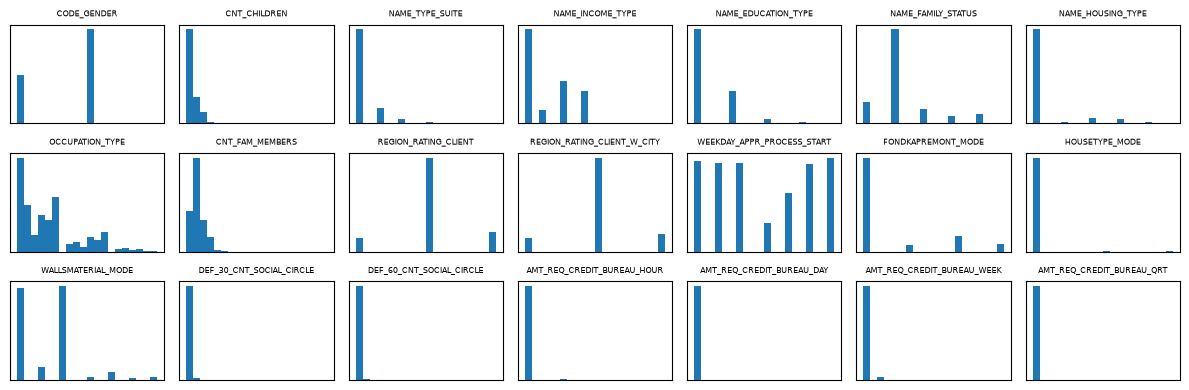

In [19]:
#графики распределений бинарных факторов
fig, axis = plt.subplots(3, 7, figsize = (12, 4))
for i, factor in enumerate(cat_factors):
    axis[i//7, i%7].hist(train_df[factor].dropna(), bins=20)
    axis[i//7, i%7].set_title(factor, fontsize=6)
    axis[i//7, i%7].set_xticks([])
    axis[i//7, i%7].set_yticks([])
plt.tight_layout()
plt.show()

In [23]:
import ipywidgets as widgets
def show_dist(factor, bins=30):
    plt.figure(figsize=(8, 4))
    plt.hist(train_df[factor].dropna(), bins=bins, edgecolor='white')
    plt.title(f'Распределение: {factor}')
    plt.xlabel(factor)
    plt.ylabel('Частота')
    plt.tight_layout()
    plt.show()

widgets.interact(
    show_dist,
    factor=widgets.Select(options=factors),
    bins=widgets.IntSlider(min=5, max=100, step=5, value=30),
)

interactive(children=(Select(description='factor', options=('NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR…

<function __main__.show_dist(factor, bins=30)>

## 3. Отбор факторов.
1. Исследование факторов на корреляцию между собой.
2. Исследование на мультиколлинеарность.
3. Исследование на корреляцию с целевой переменной

In [24]:
from sklearn.model_selection  import train_test_split
x_train, x_test, y_train, y_test = train_test_split(train_df[factors], train_df['TARGET'], test_size = 0.2, shuffle=True, random_state = 42)

In [25]:
x_train[num_factors].dtypes

AMT_INCOME_TOTAL              float64
AMT_CREDIT                    float64
AMT_ANNUITY                   float64
AMT_GOODS_PRICE               float64
REGION_POPULATION_RELATIVE    float64
                               ...   
OBS_30_CNT_SOCIAL_CIRCLE      float64
OBS_60_CNT_SOCIAL_CIRCLE      float64
DAYS_LAST_PHONE_CHANGE        float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 63, dtype: object

In [26]:
len(num_factors)

63

In [27]:
num_factors.remove('ORGANIZATION_TYPE')

In [28]:
from sklearn.feature_selection import SelectKBest, f_classif, chi2, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  LabelEncoder()),
])
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler())
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe,     num_factors),
    #('cat', cat_pipe, cat_factors),
], remainder='drop')
rfe_estimator = LogisticRegression(
    max_iter=1000,
    class_weight='balanced', # Important for Home Credit's 8% default rate
    solver='liblinear',
    random_state=42
)

pipe = Pipeline([
    ('prep',            preprocessor),
    ('select_filter',   SelectKBest(mutual_info_classif, k=50)),
    ('select_wrapper',  RFE(rfe_estimator, n_features_to_select=20, step=5)),
#    ('model',           RandomForestClassifier(random_state=42)),
])
fit_pipe = pipe.fit(x_train[num_factors], y_train)

In [29]:
fit_pipe['select_wrapper'].ranking_


array([1, 1, 1, 7, 6, 3, 7, 1, 1, 1, 1, 1, 2, 6, 6, 1, 1, 3, 1, 1, 4, 7,
       3, 7, 1, 2, 2, 6, 4, 3, 4, 5, 4, 1, 1, 1, 3, 1, 1, 5, 1, 1, 7, 5,
       6, 2, 2, 4, 5, 5])

In [30]:
prep = pipe.named_steps['prep']
skb  = pipe.named_steps['select_filter']
rfe  = pipe.named_steps['select_wrapper']

# feature names after preprocessing
try:
    names = np.asarray(prep.get_feature_names_out())
except AttributeError:
    names = np.asarray(prep.get_feature_names())

# keep only the 50 that SelectKBest passed through
sel_idx = np.where(skb.get_support())[0]
kept_names = names[sel_idx]

df50 = pd.DataFrame({
    'feature'   : kept_names,
    'skb_score' : skb.scores_[sel_idx],
    'rfe_rank'  : rfe.ranking_,          # length == 50; 1 = kept by RFE, 2..50 = eliminated
    'rfe_kept'  : rfe.support_,          # True for the final 20
})

# final rank 1..50 within these 50:
#   rfe_rank == 1  -> 1..20  (kept by RFE)
#   rfe_rank 2..50 -> 21..50 (ordered by when RFE dropped them, best-first)
df50['final_rank'] = np.where(
    df50['rfe_kept'],
    df50['rfe_rank'],
    20 + df50['rfe_rank'] - 1
)

df50 = df50.sort_values('final_rank').reset_index(drop=True)
print(df50)

                            feature  skb_score  rfe_rank  rfe_kept  final_rank
0                   num__AMT_CREDIT   0.007359         1      True           1
1                  num__AMT_ANNUITY   0.011491         1      True           1
2              num__AMT_GOODS_PRICE   0.005285         1      True           1
3                 num__EXT_SOURCE_1   0.008416         1      True           1
4              num__YEARS_BUILD_AVG   0.008113         1      True           1
5             num__BASEMENTAREA_AVG   0.014129         1      True           1
6                 num__EXT_SOURCE_3   0.014632         1      True           1
7                 num__EXT_SOURCE_2   0.011795         1      True           1
8                num__FLOORSMAX_AVG   0.009952         1      True           1
9               num__LIVINGAREA_AVG   0.009759         1      True           1
10        num__LIVINGAPARTMENTS_AVG   0.008530         1      True           1
11               num__FLOORSMIN_AVG   0.003803      

## 4. Базовый биннинг и woe

In [31]:
shortlist = df50.loc[:19, 'feature'].tolist()
shortlist = [v[5:] for v in shortlist]
shortlist

['AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'EXT_SOURCE_1',
 'YEARS_BUILD_AVG',
 'BASEMENTAREA_AVG',
 'EXT_SOURCE_3',
 'EXT_SOURCE_2',
 'FLOORSMAX_AVG',
 'LIVINGAREA_AVG',
 'LIVINGAPARTMENTS_AVG',
 'FLOORSMIN_AVG',
 'COMMONAREA_MODE',
 'COMMONAREA_MEDI',
 'YEARS_BUILD_MEDI',
 'BASEMENTAREA_MEDI',
 'FLOORSMAX_MEDI',
 'LIVINGAREA_MEDI',
 'LIVINGAPARTMENTS_MEDI',
 'FLOORSMIN_MEDI']

In [32]:
from optbinning import OptimalBinning, BinningProcess, Scorecard


binning_process = BinningProcess(variable_names=shortlist, max_n_bins=7,
    min_bin_size=0.05)
binning_process.fit(x_train[shortlist], y_train)

,variable_names,"['AMT_CREDIT', 'AMT_ANNUITY', ...]"
,max_n_bins,7
,min_bin_size,0.05
,max_n_prebins,20
,min_prebin_size,0.05
,min_n_bins,None
,max_bin_size,None
,max_pvalue,None
,max_pvalue_policy,'consecutive'
,selection_criteria,None
,fixed_variables,None


In [33]:
summary = binning_process.summary()
print(summary)

                     name      dtype   status  selected n_bins        iv  \
0              AMT_CREDIT  numerical  OPTIMAL      True      7  0.061005   
1             AMT_ANNUITY  numerical  OPTIMAL      True      7  0.032505   
2         AMT_GOODS_PRICE  numerical  OPTIMAL      True      7  0.095515   
3            EXT_SOURCE_1  numerical  OPTIMAL      True      5  0.145016   
4         YEARS_BUILD_AVG  numerical  OPTIMAL      True      4  0.017701   
5        BASEMENTAREA_AVG  numerical  OPTIMAL      True      4  0.021846   
6            EXT_SOURCE_3  numerical  OPTIMAL      True      7  0.336997   
7            EXT_SOURCE_2  numerical  OPTIMAL      True      7  0.310578   
8           FLOORSMAX_AVG  numerical  OPTIMAL      True      4  0.038228   
9          LIVINGAREA_AVG  numerical  OPTIMAL      True      7  0.034448   
10   LIVINGAPARTMENTS_AVG  numerical  OPTIMAL      True      5  0.018557   
11          FLOORSMIN_AVG  numerical  OPTIMAL      True      3  0.019469   
12        CO

In [34]:
estimator = LogisticRegression(
    solver="lbfgs",
    C=1.0,
    max_iter=1000,
)

scorecard = Scorecard(
    binning_process=binning_process,
    estimator=estimator,
    scaling_method="pdo_odds",          # or "min_max"
    scaling_method_params={
        "pdo": 20,                      # points to double the odds
        "odds": 50,                     # odds at the reference score
        "scorecard_points": 600,        # reference score
    },
    reverse_scorecard=False,            # set True if higher score = higher risk
    rounding=True,                      # round points to integers
    verbose=False,
)

scorecard.fit(x_train[shortlist], y_train)

,binning_process,BinningProces...ORSMIN_MEDI'])
,estimator,LogisticRegre...max_iter=1000)
,scaling_method,'pdo_odds'
,scaling_method_params,"{'odds': 50, 'pdo': 20, 'scorecard_points': 600}"
,rounding,True
,intercept_based,False
,reverse_scorecard,False
,verbose,False
Name,Type,Value
binning_process_,BinningProcess,BinningProces...ORSMIN_MEDI'])
estimator_,LogisticRegression,LogisticRegre...max_iter=1000)


In [35]:
scorecard_table_summary = scorecard.table(style="detailed")
print(scorecard_table_summary)


          Variable  Bin id                     Bin   Count  Count (%)  \
0       AMT_CREDIT       0       (-inf, 158105.25)   17258   0.070152   
1       AMT_CREDIT       1  [158105.25, 281884.50)   48163   0.195778   
2       AMT_CREDIT       2  [281884.50, 544770.00)   67894   0.275983   
3       AMT_CREDIT       3  [544770.00, 640269.00)   19527   0.079375   
4       AMT_CREDIT       4  [640269.00, 899163.00)   40790   0.165808   
..             ...     ...                     ...     ...        ...   
0   FLOORSMIN_MEDI       0            (-inf, 0.20)   26401   0.107318   
1   FLOORSMIN_MEDI       1            [0.20, 0.22)   26966   0.109614   
2   FLOORSMIN_MEDI       2             [0.22, inf)   25687   0.104415   
3   FLOORSMIN_MEDI       3                 Special       0   0.000000   
4   FLOORSMIN_MEDI       4                 Missing  166954   0.678653   

    Non-event  Event  Event rate       WoE        IV        JS  Coefficient  \
0       16212   1046    0.060610  0.309172  

In [36]:
raw_scores = scorecard.score(train_df[shortlist])


In [37]:
raw_scores.shape

(307511,)

In [38]:

# Обучаем логистическую регрессию для калибровки
calibrator = LogisticRegression()
calibrator.fit(raw_scores.reshape(-1, 1), train_df['TARGET'])


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

## 5. Обучение логистической регрессии

## 6. Калибровка

## 7. Тестирование результата и коммит.

H0 - гипотеза - все нули. Используем как baseline вариант для оценки прогресса.

In [39]:
val_df = pd.read_csv('../data/application_test.csv')
ids = val_df.pop('SK_ID_CURR')

probs = [0]*len(ids)

output = pd.DataFrame({'SK_ID_CURR': ids,
                       'TARGET': probs})
output.to_csv('./submission_0.csv', index=False)

In [41]:
# Получаем откалиброванные вероятности для тестовой выборки
raw_test = scorecard.score(val_df[shortlist])
calibrated_probs = calibrator.predict_proba(raw_test.reshape(-1, 1))[:,1]

output = pd.DataFrame({'SK_ID_CURR': ids,
                       'TARGET': calibrated_probs})
output.to_csv('./submission.csv', index=False)
